Accuracy: 0.7125514639113454
Macro F1: 0.5996397163708683
Weighted F1: 0.7311476184709649

Classification Report:
              precision    recall  f1-score   support

           1       0.68      0.76      0.71     10393
           2       0.41      0.57      0.48      5951
           3       0.44      0.57      0.49      8511
           4       0.41      0.57      0.47     16110
           5       0.93      0.77      0.84     72464

    accuracy                           0.71    113429
   macro avg       0.57      0.65      0.60    113429
weighted avg       0.77      0.71      0.73    113429



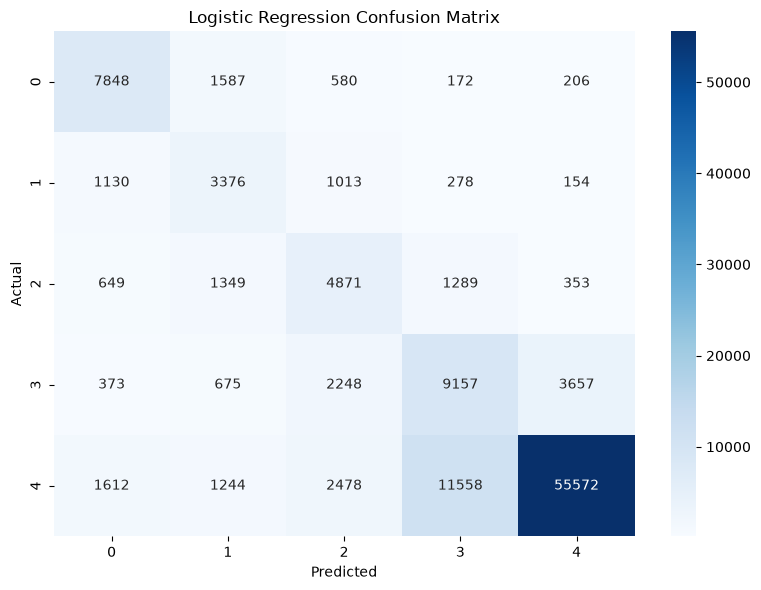

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. 加载数据
df = pd.read_csv("../data/processed/reviews_cleaned.csv")

X = df["Text"].fillna("")
y = df["Score"]

# 2. 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. TF-IDF 特征提取
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# 4. 训练模型
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    solver="lbfgs"
)

model.fit(X_train_tfidf, y_train)

# 5. 模型评估
y_pred = model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print("Weighted F1:", f1_score(y_test, y_pred, average="weighted"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 6. 混淆矩阵
plt.figure(figsize=(8, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.savefig("../results/figures/logistic_confusion_matrix.png", dpi=300)
plt.show()